# Myocardial infarction: no intercept, exactly matched penalties

This is the preferred sensitivity comparison: centered and whitened predictors,
**no fitted intercept**, and the **same logistic coefficient fit** (same penalty
family, strength, weights and normalization) reused in auxiliary signal-strength
estimation and posterior-input construction. The outcome remains logistic.
L1 and L2 constants are $10^{-8},10^{-7},10^{-6},10^{-5},10^{-4}$, on a weighted
mean-loss scale; L2 means $\lambda\|\beta\|_2^2$, without a factor of one-half.
Small constants are preferred, but numerical diagnostics and all outcomes are shown.

There are 1,692 observations and 110 predictors. Missing predictor values are mean
imputed; centered covariance whitening uses a $10^{-6}I$ ridge, followed by division
by $\sqrt n$. The prior gives 0 and 1 change point probability $1/2$ each, with
uniform location conditional on one change over 61 proper distinct-age splits.
Minimum segment size is $\Delta=1$. The signal-strength heuristic starts at $I_2$,
uses damping 0.25, projects eigenvalues to $[10^{-4},100]$, and is saved after
1, 3, 10 and 30 updates. Nonzero equation residuals are retained and reported.

Primary posterior states use 512 Sobol draws (seed 42), at most 100 state-solver
evaluations, and 160-node Gaussian quadrature for reported probabilities. Independent
checks use 1,024 draws (seed 123). The smallest strength is checked at **every**
iteration count regardless of outcome; the closest eligible curve in each family
is also checked. This latter comparison is explicitly outcome-guided exploration,
not independent-data validation or calibrated selection.

The penalties stabilize coefficient fits; they are **not** added to the posterior
log likelihood. Approximately unpenalized state equations are still used, so these
finite-iteration penalized-fit calculations remain heuristic. In particular,
centering predictors does not replace a logistic intercept: the zero-offset
Gaussian model implies marginal response probability 1/2, whereas the observed rate
is about 0.232. No-intercept results are preferred by request, not because that
model mismatch has disappeared. Intercept-aware results remain a separate sensitivity.
The conditional prior itself places 35/61 (about 0.574) mass above age 55.


In [1]:
"""Preferred sensitivity: centered X, no intercept, identical logistic penalties.

Strengths are on the weighted mean-loss scale. These are finite-iteration
heuristics; fitting penalties are not inserted into the posterior likelihood.
All settings, including nonconverged fits and undesired outcomes, are retained.
"""
from tools.myocardial_exploration import *
from tools.myocardial_exact_penalty import matched_specifications, is_exact_match
from tools.myocardial_exploration_refinement import evaluate_refined
from tools.myocardial_independent_draw_check import independent_state


def prepare_matched(spec, setting, X, y, root):
    family, strength = spec
    name = f'{family}_{strength:g}'
    path = root/('aux_'+name+'.pkl')
    if path.exists():return pickle.load(path.open('rb'))
    fit = setting['fits'].get(name)
    if fit is None:fit = fit_logistic(X, y, setting['phi'], family, strength)
    assert is_exact_match(family, strength, fit['penalty'], fit['strength'])
    scenarios = [s for s in setting['scenarios'] if s['auxiliary'] == name]
    if not scenarios:
        eta, psi = pilot(fit['theta'], y, setting['eta'], 'logistic')
        S = fit['V'].T@fit['V']/len(y)
        import WERM.myocardial_approximate as implementation
        from WERM.myocardial_numerics import logistic_prox_fast
        old = implementation.logistic_prox
        implementation.logistic_prox = logistic_prox_fast
        try:
            scenarios = [dict(r, auxiliary=name, pilot=eta, loss='logistic')
                for r in rho_path(S, setting['phi'], psi, len(y)/X.shape[1], 'logistic')]
        finally:implementation.logistic_prox = old
    result = (name, fit, scenarios)
    atomic_save(path, result)
    print('No-intercept matched auxiliary ready:', name, flush=True)
    return result


def score(rec, states, fit, setting, X, y, ages, reference, seed_label):
    ll = []
    for e, state in zip(setting['eta'], states):
        psi = np.zeros(len(y), int) if e < 0 else (np.arange(len(y)) >= e).astype(int)
        ll.append(gaussian_logistic_loglikelihood(fit['V'], y, rec['scenario']['rho'],
            state['lambda'], state['kappa'], psi, quadrature_order=160))
    ll = np.asarray(ll); joint = ll+np.log(setting['prior'])
    probs = np.exp(joint-logsumexp(joint)); curve = np.exp(ll[1:]-logsumexp(ll[1:]))
    return dict(case=rec['label'], penalty=fit['penalty'], strength=fit['strength'],
        seed_label=seed_label, P_1=probs[1:].sum(),
        mass_above55=curve[ages[setting['eta'][1:]]>55].sum(),
        peak_age=ages[setting['eta'][1:][np.argmax(curve)]], conditional=curve,
        TV_to_reference=.5*np.abs(curve-reference).sum(),
        moment_residual=rec['scenario']['moment_residual'],
        FP_residual_max=max(s['training_residual'] for s in states),
        fit_kkt_max=max(c['kkt'] for c in fit['checks']),
        fit_success=all(c['success'] for c in fit['checks']),
        iteration=rec['scenario']['iteration'], exact_match=True, fit_intercept=False)


def run(output):
    X, y, ages, locations = load_data()
    setting = pickle.load((output/'fits_delta1.pkl').open('rb'))
    root = output/'exact_matching_no_intercept'; root.mkdir(exist_ok=True)
    reference = pickle.load(open('results/myocardial_infarction_posterior_exact_one_chgpt.pkl', 'rb'))
    a = np.asarray(reference['unique_ages']).ravel(); p = np.asarray(reference['posterior']).ravel()
    keep = np.isin(a, ages[locations]); a, p = a[keep], p[keep]; p = p/p.sum()
    mapping = dict(zip(a,p)); reference_curve = np.array([mapping[v] for v in ages[locations]])
    with parallel_config(backend='loky', inner_max_num_threads=1):
        prepared = Parallel(n_jobs=10)(delayed(prepare_matched)(spec, setting, X, y, root)
                                      for spec in matched_specifications())
        tasks = [(name, fit, scenario) for name, fit, scenarios in prepared for scenario in scenarios]
        records = Parallel(n_jobs=36)(delayed(evaluate_refined)(
            dict(setting, fits={name:fit}), scenario, X, y, ages, root, 9, 100)
            for name, fit, scenario in tasks)
    rows = []
    for rec, (name, fit, scenario) in zip(records, tasks):
        result = score(rec, rec['states'], fit, setting, X, y, ages, reference_curve, 'seed42_q9')
        atomic_save(root/(rec['label']+'_score.pkl'), result)
        rows.append({k:v for k,v in result.items() if k != 'conditional'})
    summary = pd.DataFrame(rows).sort_values(['penalty','strength','iteration'])
    summary.to_csv(root/'summary.csv', index=False)
    # Independent checks of the smallest strength at all iteration counts,
    # irrespective of outcome, plus closest eligible curve per family.
    smallest = summary[summary.strength == summary.strength.min()]
    eligible = summary[(summary.P_1>.5)&(summary.mass_above55>.5)]
    closest = eligible.sort_values('TV_to_reference').groupby('penalty').head(1)
    selected = pd.concat([smallest, closest]).drop_duplicates('case')
    by_case = {r['label']:(r,t) for r,t in zip(records,tasks)}
    checks = []
    for row in selected.itertuples():
        rec, (name, fit, scenario) = by_case[row.case]
        path = root/(row.case+'_independent.pkl')
        if path.exists():states = pickle.load(path.open('rb'))
        else:
            with parallel_config(backend='loky', inner_max_num_threads=1):
                states = Parallel(n_jobs=36)(delayed(independent_state)(scenario['rho'], setting['phi'],
                    e, len(y), len(y)/X.shape[1]) for e in setting['eta'])
            atomic_save(path, states)
        result = score(rec, states, fit, setting, X, y, ages, reference_curve, 'seed123_q10')
        result['primary_P_1'] = row.P_1
        atomic_save(root/(row.case+'_independent_score.pkl'), result)
        checks.append({k:v for k,v in result.items() if k != 'conditional'})
        pd.DataFrame(checks).to_csv(root/'independent_validation.csv', index=False)
    print('No-intercept exact-match exploration complete:',len(summary),'primary settings.',flush=True)
    return summary, pd.DataFrame(checks)




/scratch/ga442/gab-code-env/papers/WeightedERM-reference/.venv-phase1/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import jax
jax.config.update('jax_enable_x64', True)
output = Path('results/myocardial_exploration_4026d0e775d2')
summary, independent = run(output)
root = output/'exact_matching_no_intercept'
display(summary)
display(independent)


No-intercept exact-match exploration complete: 40 primary settings.


,case,penalty,strength,seed_label,P_1,mass_above55,peak_age,TV_to_reference,moment_residual,FP_residual_max,fit_kkt_max,fit_success,iteration,exact_match,fit_intercept
0,d1_l1_1e-08_it1_q9_b100,l1,1.000000e-08,seed42_q9,1.000000e+00,1.000000,86.0,0.938114,3833.746907,7.583884e-10,9.911577e-10,True,1,True,False
1,d1_l1_1e-08_it3_q9_b100,l1,1.000000e-08,seed42_q9,1.000000e+00,0.000000,27.0,0.986594,3832.839053,6.485085e-06,9.911577e-10,True,3,True,False
2,d1_l1_1e-08_it10_q9_b100,l1,1.000000e-08,seed42_q9,1.000000e+00,0.000000,27.0,0.986594,3832.513294,7.862495e-04,9.911577e-10,True,10,True,False
3,d1_l1_1e-08_it30_q9_b100,l1,1.000000e-08,seed42_q9,0.000000e+00,0.000000,32.0,0.986498,3832.483093,1.094920e-03,9.911577e-10,True,30,True,False
4,d1_l1_1e-07_it1_q9_b100,l1,1.000000e-07,seed42_q9,1.000000e+00,1.000000,83.0,0.924679,2986.500729,7.548202e-10,6.538369e-10,True,1,True,False
5,d1_l1_1e-07_it3_q9_b100,l1,1.000000e-07,seed42_q9,1.000000e+00,1.000000,88.0,0.949658,2985.590883,6.487194e-06,6.538369e-10,True,3,True,False
6,d1_l1_1e-07_it10_q9_b100,l1,1.000000e-07,seed42_q9,1.000000e+00,1.000000,92.0,0.950234,2985.264297,7.862495e-04,6.538369e-10,True,10,True,False
7,d1_l1_1e-07_it30_q9_b100,l1,1.000000e-07,seed42_q9,1.000000e+00,1.000000,92.0,0.950234,2985.234014,1.094910e-03,6.538369e-10,True,30,True,False
8,d1_l1_1e-06_it1_q9_b100,l1,1.000000e-06,seed42_q9,1.000000e+00,1.000000,85.0,0.941851,2583.204931,7.590861e-10,4.844555e-10,True,1,True,False
9,d1_l1_1e-06_it3_q9_b100,l1,1.000000e-06,seed42_q9,1.000000e+00,1.000000,92.0,0.950234,2582.295972,6.487194e-06,4.844555e-10,True,3,True,False


,case,penalty,strength,seed_label,P_1,mass_above55,peak_age,TV_to_reference,moment_residual,FP_residual_max,fit_kkt_max,fit_success,iteration,exact_match,fit_intercept,primary_P_1
0,d1_l1_1e-08_it1_q9_b100,l1,1.000000e-08,seed123_q10,1.000000e+00,1.000000,88.0,0.949658,3833.746907,5.926723e-10,9.911577e-10,True,1,True,False,1.000000e+00
1,d1_l1_1e-08_it3_q9_b100,l1,1.000000e-08,seed123_q10,0.000000e+00,1.000000,92.0,0.950234,3832.839053,1.612862e-04,9.911577e-10,True,3,True,False,1.000000e+00
2,d1_l1_1e-08_it10_q9_b100,l1,1.000000e-08,seed123_q10,0.000000e+00,0.000000,27.0,0.986594,3832.513294,9.745717e-04,9.911577e-10,True,10,True,False,1.000000e+00
3,d1_l1_1e-08_it30_q9_b100,l1,1.000000e-08,seed123_q10,0.000000e+00,0.000000,27.0,0.986594,3832.483093,9.734095e-04,9.911577e-10,True,30,True,False,0.000000e+00
4,d1_l2_1e-08_it1_q9_b100,l2,1.000000e-08,seed123_q10,1.000000e+00,1.000000,83.0,0.909037,1148.786503,6.112984e-10,2.162753e-10,True,1,True,False,1.000000e+00
5,d1_l2_1e-08_it3_q9_b100,l2,1.000000e-08,seed123_q10,9.994357e-01,1.000000,92.0,0.950234,1132.727166,1.861924e-04,2.162753e-10,True,3,True,False,1.000000e+00
6,d1_l2_1e-08_it10_q9_b100,l2,1.000000e-08,seed123_q10,0.000000e+00,1.000000,92.0,0.950234,1149.733607,2.663064e-03,2.162753e-10,True,10,True,False,0.000000e+00
7,d1_l2_1e-08_it30_q9_b100,l2,1.000000e-08,seed123_q10,3.888407e-220,0.000000,27.0,0.986594,1160.352193,1.121351e-03,2.162753e-10,True,30,True,False,2.146379e-44
8,d1_l2_0.0001_it30_q9_b100,l2,1.000000e-04,seed123_q10,5.309819e-01,0.591512,65.0,0.661420,0.493835,1.188796e-09,6.733576e-11,True,30,True,False,5.147997e-01
9,d1_l1_1e-07_it1_q9_b100,l1,1.000000e-07,seed123_q10,1.000000e+00,1.000000,84.0,0.936151,2986.500729,5.744278e-10,6.538369e-10,True,1,True,False,1.000000e+00


All exact matches: count evidence and conditional mass above 55


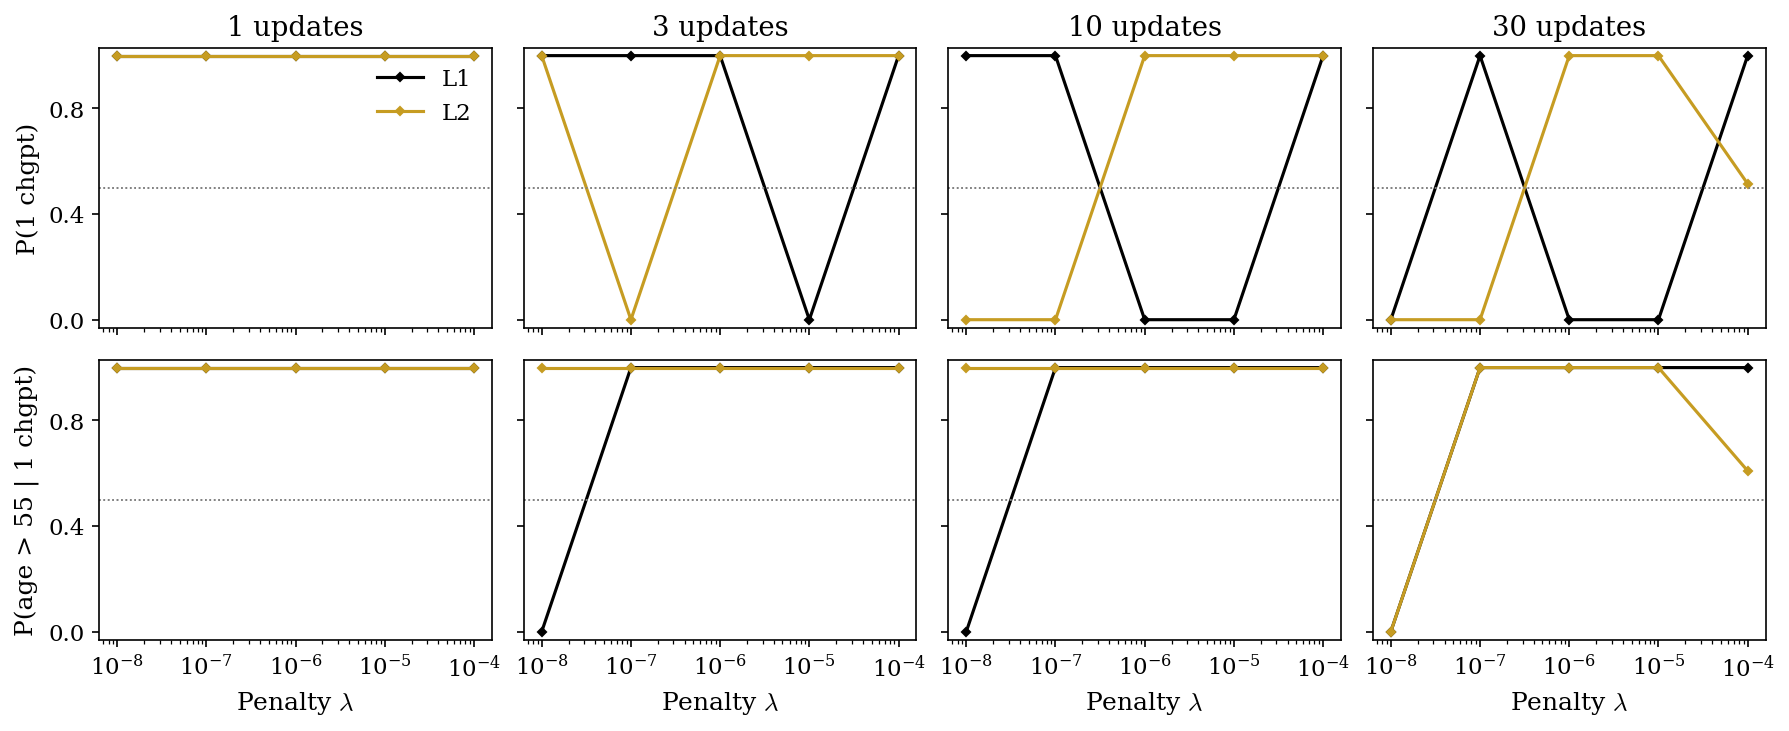

Conditional location posterior: every family, strength and iteration count
L1


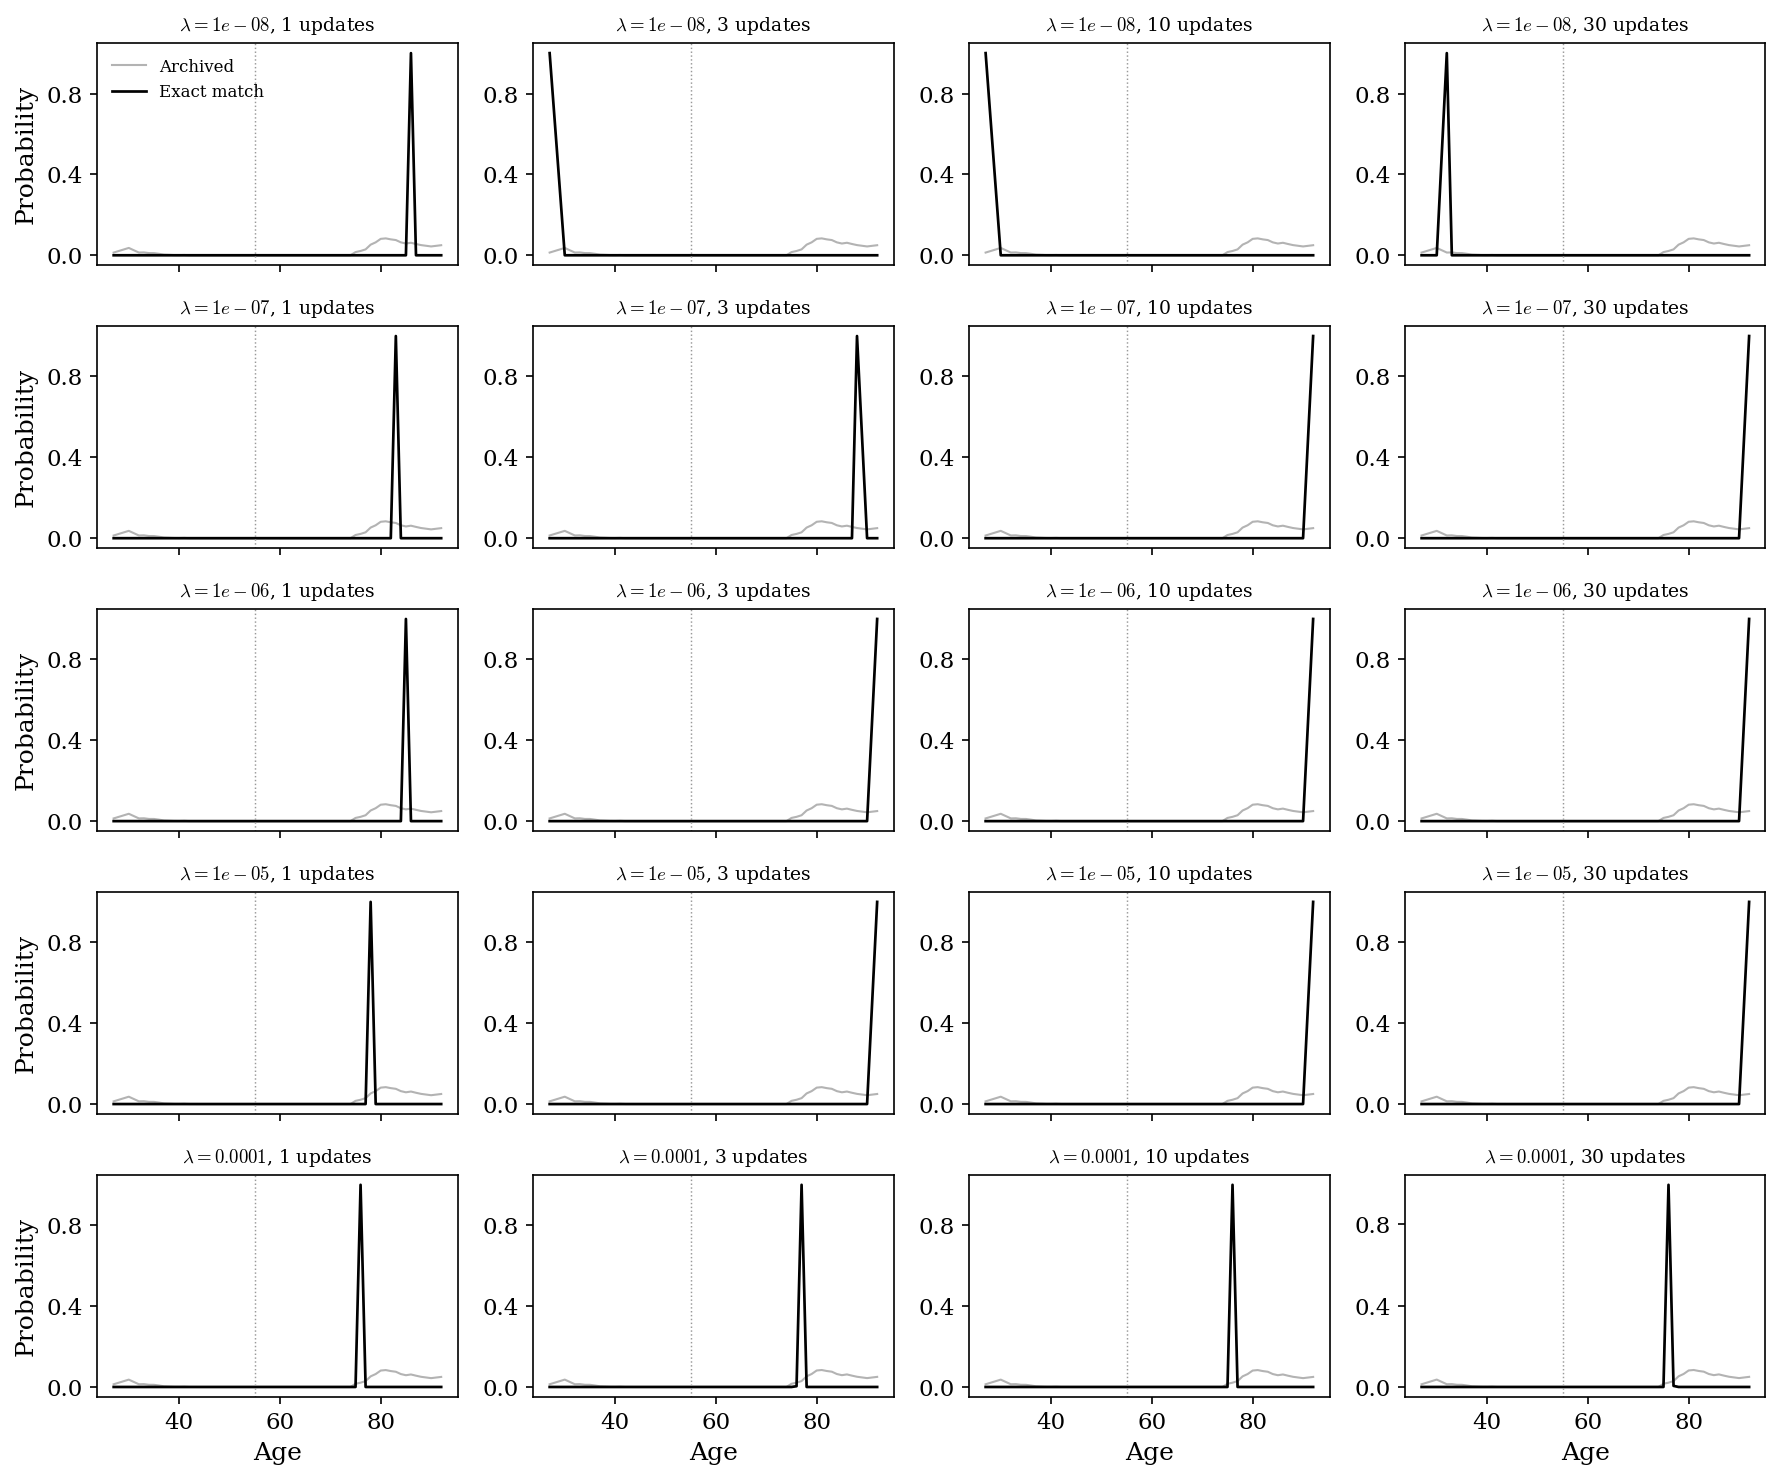

L2


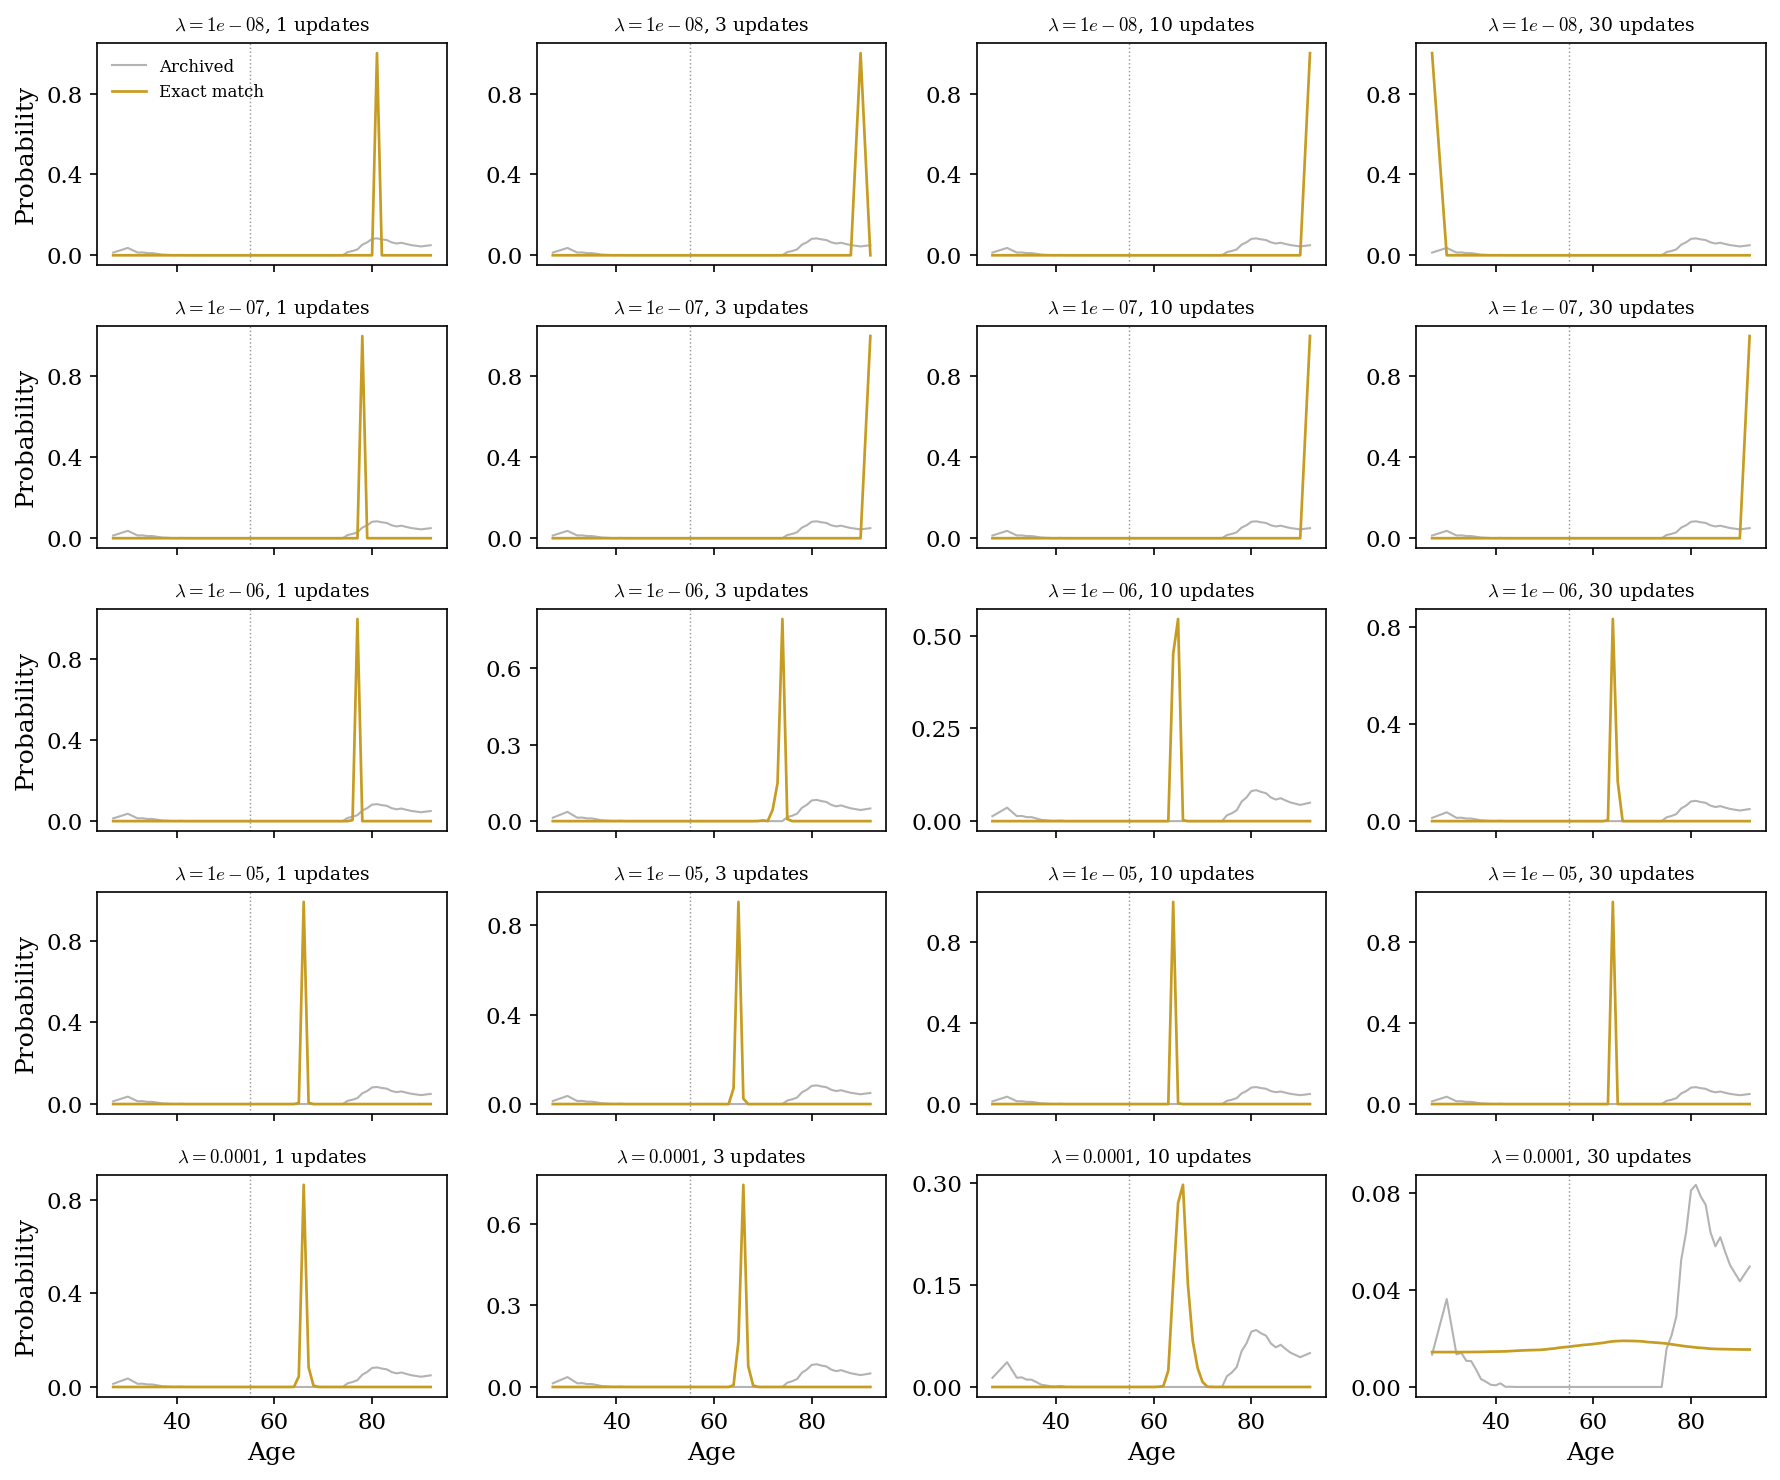

Independent numerical checks (not independent-data validation)
L1, lambda=1e-08, 1 updates: P(1)=1 / 1; moment residual=3834; max fit KKT=9.91e-10


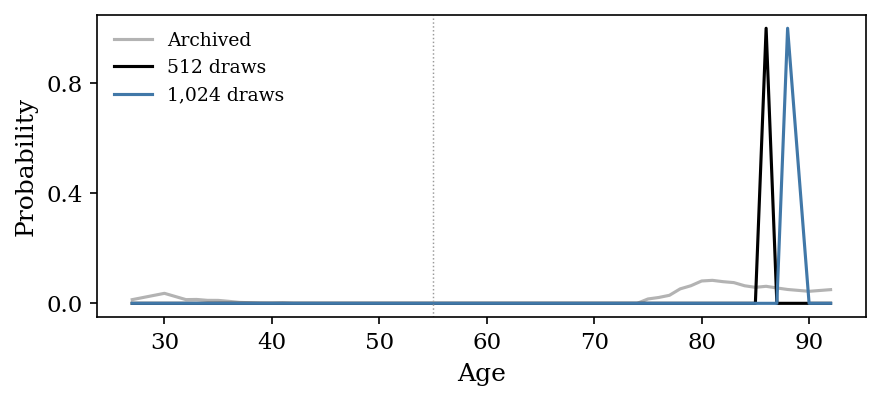

L1, lambda=1e-08, 3 updates: P(1)=1 / 0; moment residual=3833; max fit KKT=9.91e-10


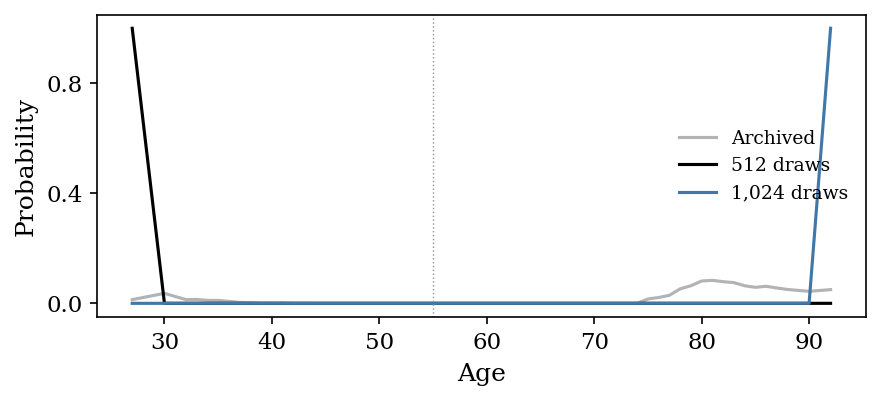

L1, lambda=1e-08, 10 updates: P(1)=1 / 0; moment residual=3833; max fit KKT=9.91e-10


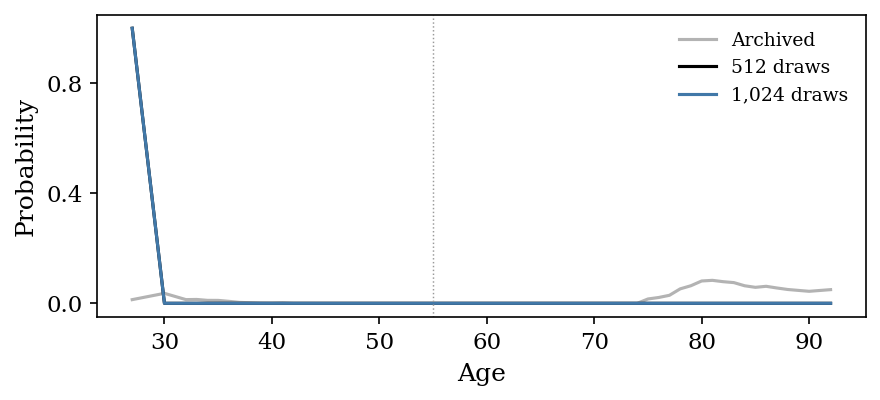

L1, lambda=1e-08, 30 updates: P(1)=0 / 0; moment residual=3832; max fit KKT=9.91e-10


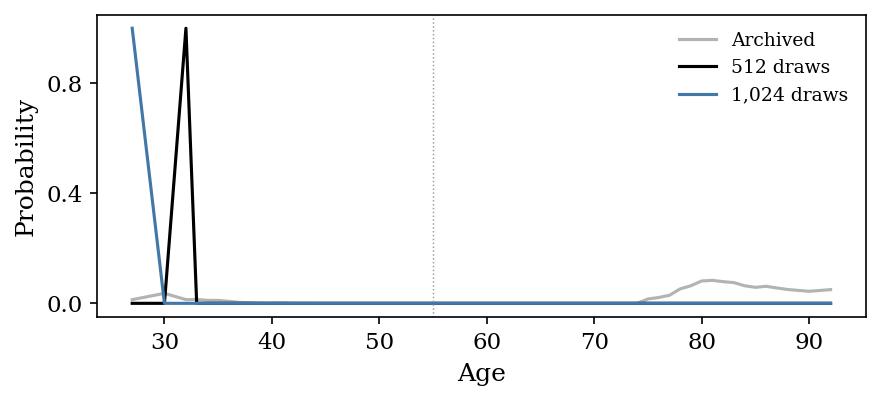

L2, lambda=1e-08, 1 updates: P(1)=1 / 1; moment residual=1149; max fit KKT=2.16e-10


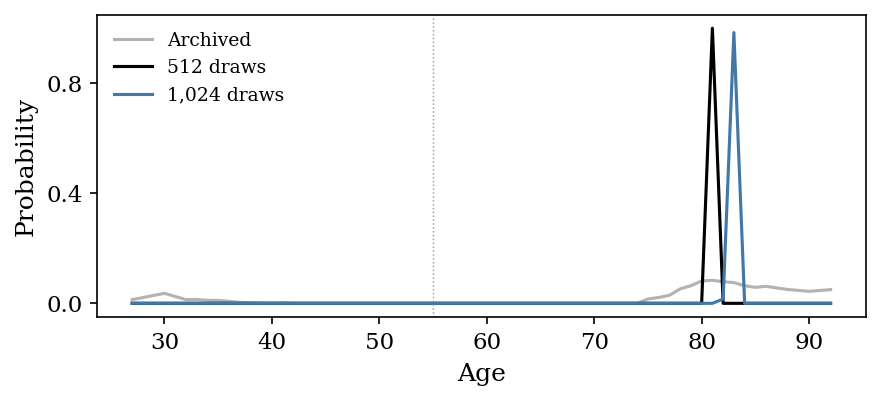

L2, lambda=1e-08, 3 updates: P(1)=1 / 0.9994; moment residual=1133; max fit KKT=2.16e-10


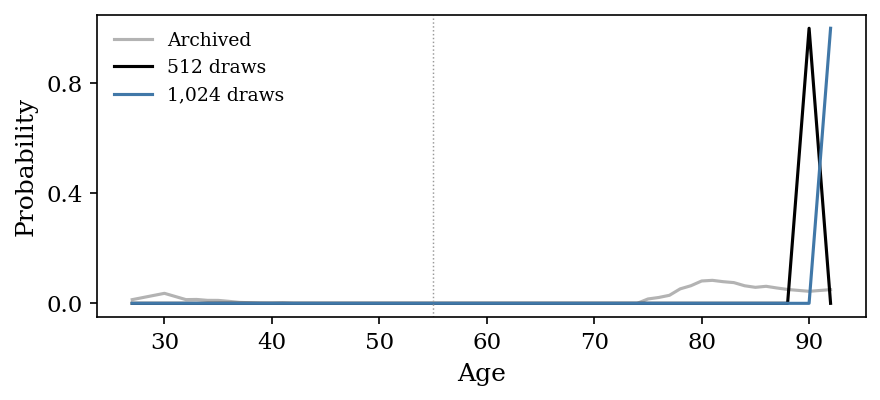

L2, lambda=1e-08, 10 updates: P(1)=0 / 0; moment residual=1150; max fit KKT=2.16e-10


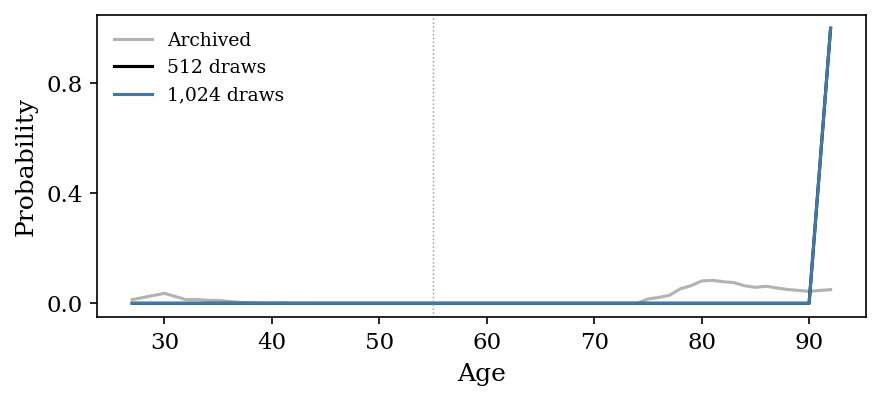

L2, lambda=1e-08, 30 updates: P(1)=2.146e-44 / 3.888e-220; moment residual=1160; max fit KKT=2.16e-10


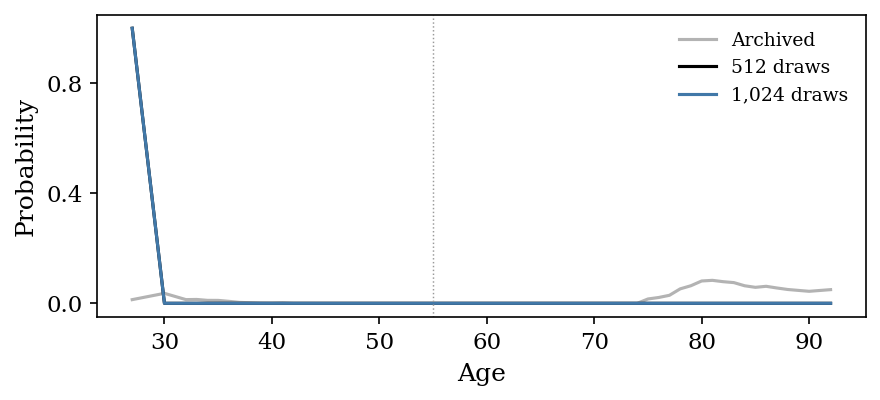

L2, lambda=0.0001, 30 updates: P(1)=0.5148 / 0.531; moment residual=0.4938; max fit KKT=6.73e-11


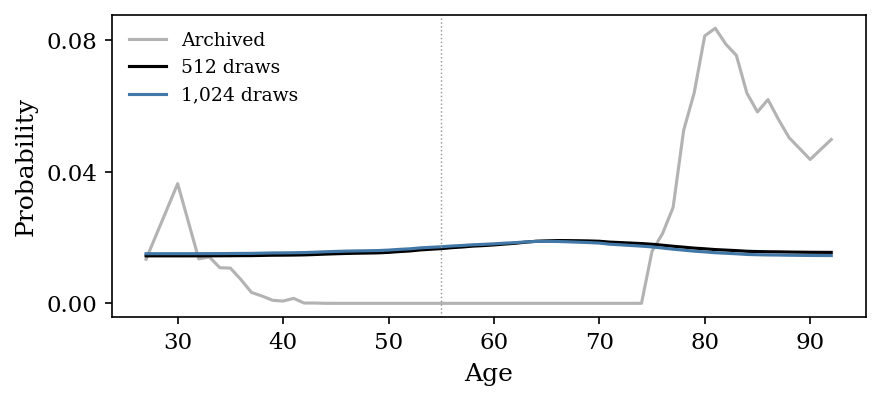

L1, lambda=1e-07, 1 updates: P(1)=1 / 1; moment residual=2987; max fit KKT=6.54e-10


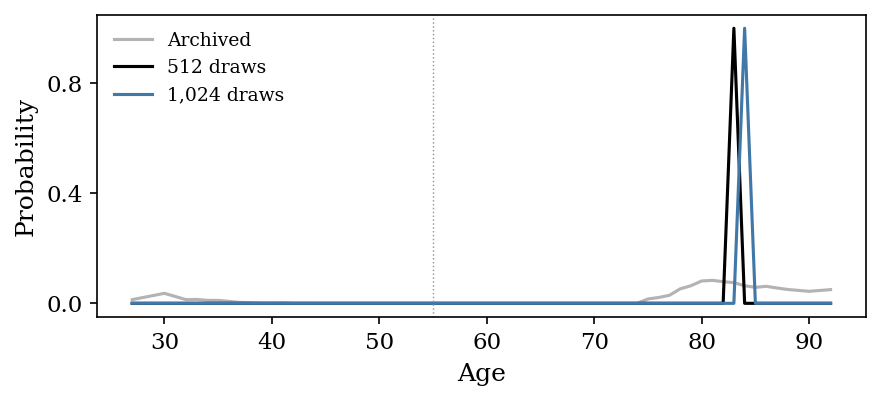

In [3]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
plt.rcParams.update({'font.family':'serif', 'mathtext.fontset':'cm',
                     'font.size':11, 'axes.labelsize':12, 'figure.dpi':150})
colors = {'l1':'black', 'l2':'#c69c22'}
print('All exact matches: count evidence and conditional mass above 55')
fig, axes = plt.subplots(2, 4, figsize=(12, 5), sharex=True, sharey='row')
for j, it in enumerate((1,3,10,30)):
    for family in ('l1','l2'):
        data = summary[(summary.iteration==it)&(summary.penalty==family)]
        for ax, key in zip(axes[:,j], ('P_1','mass_above55')):
            ax.semilogx(data.strength, data[key], '-D', ms=3, color=colors[family], label=family.upper())
            ax.axhline(.5, color='grey', ls=':', lw=.8)
            ax.set_ylim(-.03,1.03); ax.yaxis.set_major_locator(MaxNLocator(3))
    axes[0,j].set_title(f'{it} updates'); axes[1,j].set_xlabel(r'Penalty $\lambda$')
axes[0,0].set_ylabel('P(1 chgpt)'); axes[1,0].set_ylabel('P(age > 55 | 1 chgpt)')
axes[0,0].legend(frameon=False); fig.tight_layout(); plt.show()

print('Conditional location posterior: every family, strength and iteration count')
X,y,ages,locations = load_data()
ref = pickle.load(open('results/myocardial_infarction_posterior_exact_one_chgpt.pkl','rb'))
a=np.asarray(ref['unique_ages']).ravel(); p=np.asarray(ref['posterior']).ravel()
keep=np.isin(a,ages[locations]); a,p=a[keep],p[keep]; p=p/p.sum()
for family in ('l1','l2'):
    print(family.upper())
    fig, axes = plt.subplots(5,4,figsize=(12,10),sharex=True)
    for i,strength in enumerate((1e-8,1e-7,1e-6,1e-5,1e-4)):
        for j,it in enumerate((1,3,10,30)):
            row=summary[(summary.penalty==family)&(summary.strength==strength)&(summary.iteration==it)].iloc[0]
            rec=pickle.load((root/(row['case']+'_score.pkl')).open('rb'))
            ax=axes[i,j]; ax.plot(a,p,color='0.7',lw=1,label='Archived')
            ax.plot(ages[locations],rec['conditional'],color=colors[family],lw=1.3,label='Exact match')
            ax.axvline(55,color='0.6',ls=':',lw=.7)
            ax.set_title(fr'$\lambda={strength:g}$, {it} updates',fontsize=9)
            ax.yaxis.set_major_locator(MaxNLocator(3)); ax.xaxis.set_major_locator(MaxNLocator(4,integer=True))
            if j==0:ax.set_ylabel('Probability')
            if i==4:ax.set_xlabel('Age')
    axes[0,0].legend(frameon=False,fontsize=8);fig.tight_layout();plt.show()

print('Independent numerical checks (not independent-data validation)')
for row in independent.itertuples():
    primary=pickle.load((root/(row.case+'_score.pkl')).open('rb'))
    check=pickle.load((root/(row.case+'_independent_score.pkl')).open('rb'))
    print(f'{row.penalty.upper()}, lambda={row.strength:g}, {row.iteration} updates: '
          f'P(1)={primary["P_1"]:.4g} / {check["P_1"]:.4g}; '
          f'moment residual={row.moment_residual:.4g}; max fit KKT={row.fit_kkt_max:.3g}')
    fig,ax=plt.subplots(figsize=(6,2.8))
    ax.plot(a,p,color='0.7',label='Archived')
    ax.plot(ages[locations],primary['conditional'],color='black',label='512 draws')
    ax.plot(ages[locations],check['conditional'],color='#4178a8',label='1,024 draws')
    ax.axvline(55,color='0.6',ls=':',lw=.7)
    ax.set_xlabel('Age');ax.set_ylabel('Probability');ax.legend(frameon=False,fontsize=9)
    ax.yaxis.set_major_locator(MaxNLocator(3));fig.tight_layout();plt.show()


## Least-squares auxiliary alternative

The complete no-intercept least-squares auxiliary comparison, including small
logistic posterior penalties and independent numerical checks, is retained in
**Myocardial Infarction Experiment - heuristic exploration.ipynb**. It is separate
from the exact logistic/logistic matching requirement shown above.